In [1]:
import os
import gzip
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

plt.rcParams["animation.embed_limit"] = 50

In [2]:
def abrir_archivo(ruta):
    # Buscar version comprimida
    if not os.path.exists(ruta) and os.path.exists(ruta + ".gz"):
        ruta = ruta + ".gz"
    if ruta.endswith(".gz"):
        return gzip.open(ruta, "rt")
    return open(ruta)


def leer_coordenadas(ruta):
    with abrir_archivo(ruta) as archivo:
        lineas = [linea.strip() for linea in archivo]

    # Saltar encabezado TSPLIB
    if "NODE_COORD_SECTION" in lineas:
        inicio = lineas.index("NODE_COORD_SECTION") + 1
        lineas = lineas[inicio:]

    coordenadas = []
    for linea in lineas:
        if linea == "EOF":
            break
        valores = linea.replace(",", " ").split()
        if len(valores) >= 2:
            coordenadas.append([float(valor) for valor in valores[-2:]])
    return np.array(coordenadas)


def leer_matriz(ruta):
    with abrir_archivo(ruta) as archivo:
        filas = [linea.replace(",", " ").split() for linea in archivo if linea.strip()]
    return np.array(filas, dtype=float)


def matriz_desde_coordenadas(coordenadas, redondear=False):
    diferencias = coordenadas[:, None, :] - coordenadas[None, :, :]
    matriz = np.sqrt(np.sum(diferencias ** 2, axis=2))
    # Distancia entera TSPLIB
    if redondear:
        matriz = np.floor(matriz + 0.5)
    return matriz


def coordenadas_desde_matriz(matriz):
    # Escalamiento multidimensional clasico
    n = len(matriz)
    centrado = np.eye(n) - np.ones([n, n]) / n
    gram = -0.5 * centrado @ matriz ** 2 @ centrado
    valores, vectores = np.linalg.eigh(gram)
    mayores = np.argsort(valores)[::-1][:2]
    return vectores[:, mayores] * np.sqrt(np.maximum(valores[mayores], 0))


def preparar_problema(coordenadas=None, matriz=None, redondear=False):
    if coordenadas is None and matriz is None:
        raise ValueError("Se necesitan coordenadas o matriz")

    if matriz is None:
        coordenadas = np.asarray(coordenadas, dtype=float)
        matriz = matriz_desde_coordenadas(coordenadas, redondear)
    else:
        matriz = np.asarray(matriz, dtype=float)
        if not np.allclose(matriz, matriz.T):
            raise ValueError("La matriz debe ser simetrica")

    if coordenadas is None:
        coordenadas = coordenadas_desde_matriz(matriz)
    return coordenadas, matriz

In [3]:
def distancia_rutas(poblacion, matriz):
    siguientes = np.roll(poblacion, -1, axis=1)
    return matriz[poblacion, siguientes].sum(axis=1)


def convertir_cantidad(valor, total):
    if 0 < valor < 1:
        return round(valor * total)
    return int(valor)


def probabilidades(distancias, esquema, f, presion):
    n = len(distancias)
    if esquema == "ranking":
        rangos = np.empty(n)
        rangos[np.argsort(distancias)] = np.arange(n)
        if f == "exponencial":
            pesos = np.exp(-presion * rangos / n)
        else:
            pesos = n - rangos
    else:
        if f == "ventana":
            pesos = distancias.max() - distancias + 1e-9
        else:
            pesos = 1 / distancias ** presion
    return pesos / pesos.sum()


def seleccionar(distancias, cantidad, parametros, rng):
    esquema = parametros["seleccion"]
    n = len(distancias)

    if esquema == "torneo":
        competidores = rng.integers(0, n, size=[cantidad, parametros["k"]])
        ganadores = np.argmin(distancias[competidores], axis=1)
        return competidores[np.arange(cantidad), ganadores]

    if esquema == "elitismo":
        tamano_elite = max(2, convertir_cantidad(parametros["s"], n))
        elite = np.argsort(distancias)[:tamano_elite]
        return rng.choice(elite, size=cantidad)

    pesos = probabilidades(distancias, esquema, parametros["f"], parametros["presion"])
    return rng.choice(n, size=cantidad, p=pesos)

In [4]:
def cruce_ox(padre, madre, rng):
    inicio, fin = np.sort(rng.choice(len(padre), 2, replace=False))
    segmento = padre[inicio:fin]
    resto = madre[~np.isin(madre, segmento)]
    return np.concatenate([resto[:inicio], segmento, resto[inicio:]])


def mutar(ruta, rng):
    hijo = ruta.copy()
    i, j = np.sort(rng.choice(len(ruta), 2, replace=False))
    operador = rng.choice(["inversion", "intercambio", "insercion"], p=[0.6, 0.2, 0.2])

    if operador == "inversion":
        hijo[i:j + 1] = hijo[i:j + 1][::-1]
    elif operador == "intercambio":
        hijo[i], hijo[j] = hijo[j], hijo[i]
    else:
        hijo = np.insert(np.delete(hijo, j), i, hijo[j])
    return hijo


def dos_opt(ruta, matriz):
    ruta = ruta.copy()
    n = len(ruta)
    hubo_mejora = True
    while hubo_mejora:
        hubo_mejora = False
        for i in range(n - 2):
            a, b = ruta[i], ruta[i + 1]
            c, d = ruta[i + 2:], np.roll(ruta, -1)[i + 2:]
            ganancia = matriz[a, b] + matriz[c, d] - matriz[a, c] - matriz[b, d]
            j = np.argmax(ganancia)
            if ganancia[j] > 1e-9:
                j = j + i + 2
                ruta[i + 1:j + 1] = ruta[i + 1:j + 1][::-1]
                hubo_mejora = True
    return ruta


def rutas_aleatorias(cantidad, n, rng):
    rutas = [rng.permutation(n) for _ in range(cantidad)]
    return np.array(rutas, dtype=int).reshape(cantidad, n)

In [5]:
def algoritmo_genetico(matriz, N=200, maxIter=1000, seleccion="torneo", k=3, s=0.1,
                       f="lineal", presion=5, c=0.5, m=0.4, mejora_local=False, semilla=None):
    rng = np.random.default_rng(semilla)
    parametros = {"seleccion": seleccion, "k": k, "s": s, "f": f, "presion": presion}
    n = len(matriz)

    num_sobrevivientes = max(1, convertir_cantidad(s, N))
    num_cruce = convertir_cantidad(c, N)
    num_mutacion = convertir_cantidad(m, N)
    if num_sobrevivientes + num_cruce + num_mutacion > N:
        raise ValueError("s + c + m no puede superar N")

    poblacion = rutas_aleatorias(N, n, rng)
    distancias = distancia_rutas(poblacion, matriz)
    mejor_distancia = np.inf
    historial = {"mejor": [], "promedio": [], "diversidad": [], "rutas": []}

    for iteracion in range(maxIter):
        orden = np.argsort(distancias)

        # Sobrevivientes
        if seleccion == "elitismo":
            sobrevivientes = orden[:num_sobrevivientes]
        else:
            elegidos = seleccionar(distancias, num_sobrevivientes - 1, parametros, rng)
            sobrevivientes = np.concatenate([orden[:1], elegidos])
        nueva = [poblacion[i] for i in sobrevivientes]

        # Hijos por cruce
        padres = seleccionar(distancias, 2 * num_cruce, parametros, rng).reshape(-1, 2)
        for i, j in padres:
            nueva.append(cruce_ox(poblacion[i], poblacion[j], rng))

        # Hijos por mutacion
        for i in seleccionar(distancias, num_mutacion, parametros, rng):
            nueva.append(mutar(poblacion[i], rng))

        # Inmigrantes aleatorios
        inmigrantes = rutas_aleatorias(N - len(nueva), n, rng)
        nueva = np.vstack([np.array(nueva), inmigrantes])
        nuevas_distancias = distancia_rutas(nueva, matriz)

        # Reemplazar duplicados
        _, unicos = np.unique(np.round(nuevas_distancias, 6), return_index=True)
        duplicados = np.setdiff1d(np.arange(N), unicos)
        for i in duplicados:
            nueva[i] = mutar(nueva[rng.integers(N)], rng)
        nuevas_distancias[duplicados] = distancia_rutas(nueva[duplicados], matriz)

        poblacion, distancias = nueva, nuevas_distancias
        mejor = np.argmin(distancias)

        # Busqueda local opcional
        if mejora_local and distancias[mejor] < mejor_distancia:
            poblacion[mejor] = dos_opt(poblacion[mejor], matriz)
            distancias[mejor] = distancia_rutas(poblacion[mejor:mejor + 1], matriz)[0]

        if distancias[mejor] < mejor_distancia:
            mejor_distancia = distancias[mejor]
            best = poblacion[mejor].copy()
            historial["rutas"].append([iteracion, best, mejor_distancia])

        historial["mejor"].append(mejor_distancia)
        historial["promedio"].append(distancias.mean())
        historial["diversidad"].append(len(unicos) / N)

    return best, mejor_distancia, historial

In [6]:
def cerrar_ruta(ruta):
    return np.append(ruta, ruta[0])


def ordenar_desde_inicio(ruta):
    inicio = np.flatnonzero(ruta == 0)[0]
    return np.roll(ruta, -inicio)


def graficar_ruta(coordenadas, ruta, titulo, eje=None):
    if eje is None:
        _, eje = plt.subplots(figsize=[7, 5])
    cerrada = cerrar_ruta(ruta)
    eje.plot(coordenadas[cerrada, 0], coordenadas[cerrada, 1], c="tab:blue", lw=1.5)
    eje.scatter(coordenadas[:, 0], coordenadas[:, 1], c="tab:red", s=25, zorder=3)
    eje.scatter(*coordenadas[ruta[0]], c="black", s=60, marker="s", zorder=4)
    eje.set_title(titulo)
    eje.set_xticks([])
    eje.set_yticks([])


def graficar_convergencia(historial):
    figura, [eje_distancia, eje_diversidad] = plt.subplots(1, 2, figsize=[13, 4])
    eje_distancia.plot(historial["mejor"], label="Mejor")
    eje_distancia.plot(historial["promedio"], label="Promedio", alpha=0.6)
    eje_distancia.set_xlabel("Iteración")
    eje_distancia.set_ylabel("Distancia")
    eje_distancia.set_title("Evolución de la distancia")
    eje_distancia.legend()

    eje_diversidad.plot(historial["diversidad"], c="tab:green")
    eje_diversidad.set_ylim(0, 1.05)
    eje_diversidad.set_xlabel("Iteración")
    eje_diversidad.set_ylabel("Proporción de individuos distintos")
    eje_diversidad.set_title("Diversidad de la población")
    plt.tight_layout()
    plt.show()


def animar_evolucion(coordenadas, historial, max_cuadros=80, intervalo=150):
    capturas = historial["rutas"]
    if len(capturas) > max_cuadros:
        indices = np.linspace(0, len(capturas) - 1, max_cuadros).astype(int)
        capturas = [capturas[i] for i in indices]

    figura, [eje_ruta, eje_curva] = plt.subplots(1, 2, figsize=[12, 5], dpi=80)
    eje_ruta.scatter(coordenadas[:, 0], coordenadas[:, 1], c="tab:red", s=25, zorder=3)
    eje_ruta.set_xticks([])
    eje_ruta.set_yticks([])
    linea_ruta, = eje_ruta.plot([], [], c="tab:blue", lw=1.5)

    eje_curva.plot(historial["mejor"], c="lightgray")
    linea_curva, = eje_curva.plot([], [], c="tab:blue")
    punto, = eje_curva.plot([], [], "o", c="tab:red")
    eje_curva.set_xlabel("Iteración")
    eje_curva.set_ylabel("Mejor distancia")
    eje_curva.set_title("Reducción de la distancia")

    def actualizar(cuadro):
        iteracion, ruta, distancia = capturas[cuadro]
        cerrada = cerrar_ruta(ruta)
        linea_ruta.set_data(coordenadas[cerrada, 0], coordenadas[cerrada, 1])
        eje_ruta.set_title(f"Iteración {iteracion}   D = {distancia:.2f}")
        linea_curva.set_data(np.arange(iteracion + 1), historial["mejor"][:iteracion + 1])
        punto.set_data([iteracion], [distancia])
        return linea_ruta, linea_curva, punto

    animacion = FuncAnimation(figura, actualizar, frames=len(capturas), interval=intervalo)
    plt.close(figura)
    return HTML(animacion.to_jshtml())


def mostrar_resultado(best, distancia, indice_inicial=1):
    ruta = ordenar_desde_inicio(best) + indice_inicial
    print("best =", " -> ".join(str(ciudad) for ciudad in cerrar_ruta(ruta)))
    print(f"D = {distancia:.2f}")

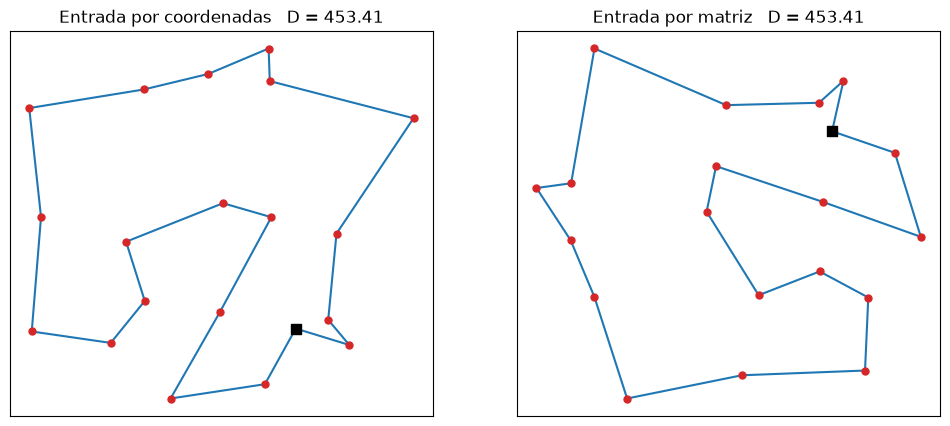

In [7]:
rng_ejemplo = np.random.default_rng(7)
coordenadas_ejemplo = rng_ejemplo.uniform(0, 100, size=[20, 2])
matriz_ejemplo = matriz_desde_coordenadas(coordenadas_ejemplo)

coords_a, matriz_a = preparar_problema(coordenadas=coordenadas_ejemplo)
coords_b, matriz_b = preparar_problema(matriz=matriz_ejemplo)

best_a, d_a, _ = algoritmo_genetico(matriz_a, N=100, maxIter=300, semilla=0)
best_b, d_b, _ = algoritmo_genetico(matriz_b, N=100, maxIter=300, semilla=0)

figura, ejes = plt.subplots(1, 2, figsize=[12, 5])
graficar_ruta(coords_a, best_a, f"Entrada por coordenadas   D = {d_a:.2f}", ejes[0])
graficar_ruta(coords_b, best_b, f"Entrada por matriz   D = {d_b:.2f}", ejes[1])
plt.show()

In [8]:
coordenadas_berlin = leer_coordenadas("berlin52.tsp")
coordenadas_berlin, matriz_berlin = preparar_problema(coordenadas_berlin, redondear=True)
OPTIMO_BERLIN = 7542

parametros = {
    "N": 300,
    "maxIter": 3000,
    "seleccion": "torneo",
    "k": 3,
    "s": 0.1,
    "c": 0.5,
    "m": 0.4,
    "semilla": 1,
}
print("Ciudades:", len(coordenadas_berlin))

Ciudades: 52


In [9]:
inicio = time.time()
best, D, historial = algoritmo_genetico(matriz_berlin, **parametros)
duracion = time.time() - inicio

mostrar_resultado(best, D)
print(f"Error respecto al óptimo: {100 * (D - OPTIMO_BERLIN) / OPTIMO_BERLIN:.2f}%")
print(f"Tiempo: {duracion:.1f} s")

best = 1 -> 22 -> 18 -> 31 -> 23 -> 20 -> 50 -> 16 -> 29 -> 30 -> 2 -> 7 -> 42 -> 21 -> 17 -> 3 -> 45 -> 19 -> 41 -> 8 -> 9 -> 10 -> 43 -> 33 -> 51 -> 11 -> 52 -> 14 -> 13 -> 47 -> 26 -> 27 -> 28 -> 12 -> 25 -> 4 -> 6 -> 15 -> 5 -> 24 -> 48 -> 38 -> 40 -> 39 -> 37 -> 46 -> 44 -> 34 -> 35 -> 36 -> 49 -> 32 -> 1
D = 7715.00
Error respecto al óptimo: 2.29%
Tiempo: 19.0 s


In [10]:
animar_evolucion(coordenadas_berlin, historial)

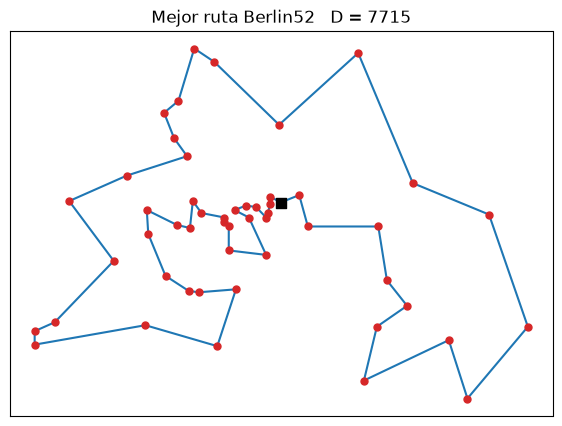

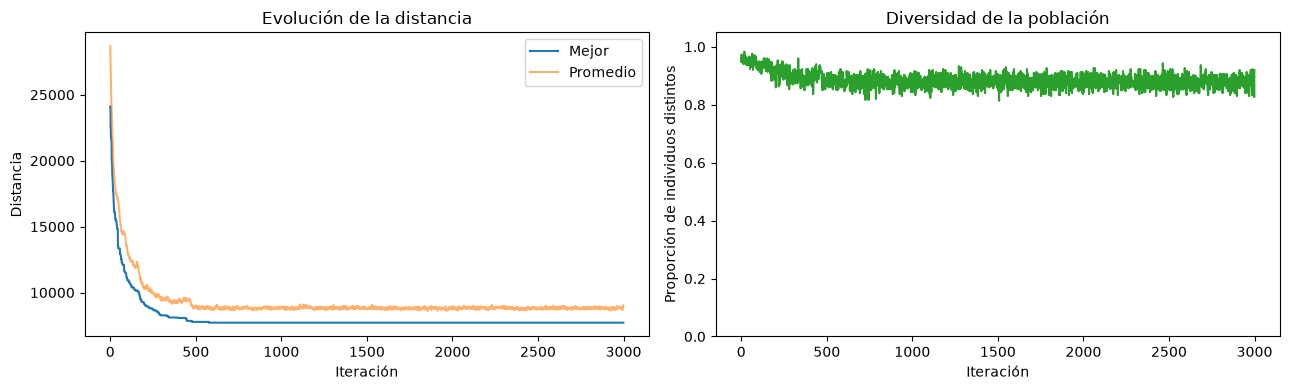

In [11]:
graficar_ruta(coordenadas_berlin, best, f"Mejor ruta Berlin52   D = {D:.0f}")
plt.show()
graficar_convergencia(historial)

Torneo k = 3           D = 7715


Ranking exponencial    D = 8203


Fitness ventana        D = 8946


Elitismo s = 0.1       D = 7994


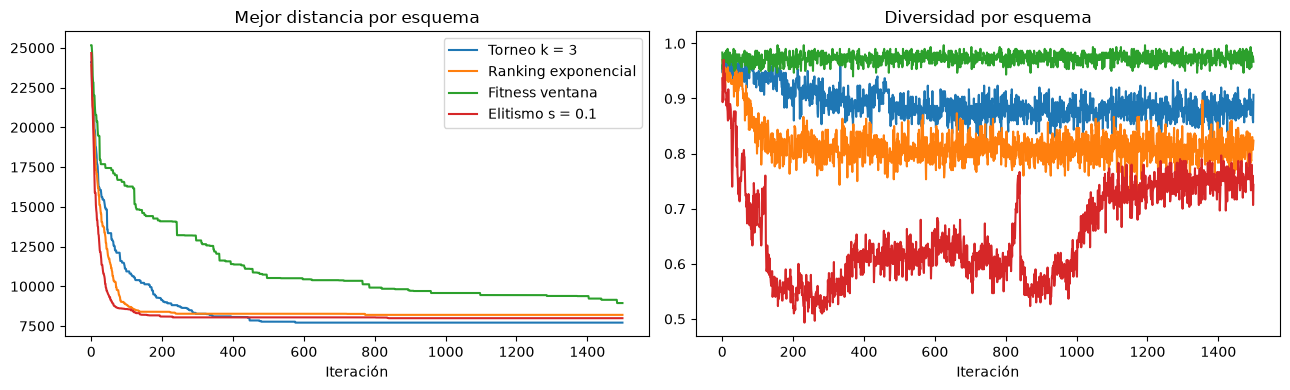

In [12]:
configuraciones = {
    "Torneo k = 3": {"seleccion": "torneo", "k": 3},
    "Ranking exponencial": {"seleccion": "ranking", "f": "exponencial", "presion": 5},
    "Fitness ventana": {"seleccion": "fitness", "f": "ventana"},
    "Elitismo s = 0.1": {"seleccion": "elitismo", "s": 0.1},
}

historiales = {}
for nombre, ajustes in configuraciones.items():
    _, distancia, historial_esquema = algoritmo_genetico(
        matriz_berlin, N=300, maxIter=1500, c=0.5, m=0.4, semilla=1, **ajustes
    )
    historiales[nombre] = historial_esquema
    print(f"{nombre:22s} D = {distancia:.0f}")

figura, [eje_distancia, eje_diversidad] = plt.subplots(1, 2, figsize=[13, 4])
for nombre, historial_esquema in historiales.items():
    eje_distancia.plot(historial_esquema["mejor"], label=nombre)
    eje_diversidad.plot(historial_esquema["diversidad"], label=nombre)
eje_distancia.set_title("Mejor distancia por esquema")
eje_distancia.set_xlabel("Iteración")
eje_distancia.legend()
eje_diversidad.set_title("Diversidad por esquema")
eje_diversidad.set_xlabel("Iteración")
plt.tight_layout()
plt.show()

best = 1 -> 22 -> 31 -> 18 -> 3 -> 17 -> 21 -> 42 -> 7 -> 2 -> 30 -> 23 -> 20 -> 50 -> 29 -> 16 -> 46 -> 44 -> 34 -> 35 -> 36 -> 39 -> 40 -> 37 -> 38 -> 48 -> 24 -> 5 -> 15 -> 6 -> 4 -> 25 -> 12 -> 28 -> 27 -> 26 -> 47 -> 13 -> 14 -> 52 -> 11 -> 51 -> 33 -> 43 -> 10 -> 9 -> 8 -> 41 -> 19 -> 45 -> 32 -> 49 -> 1
D = 7542.00
Error respecto al óptimo: 0.00%


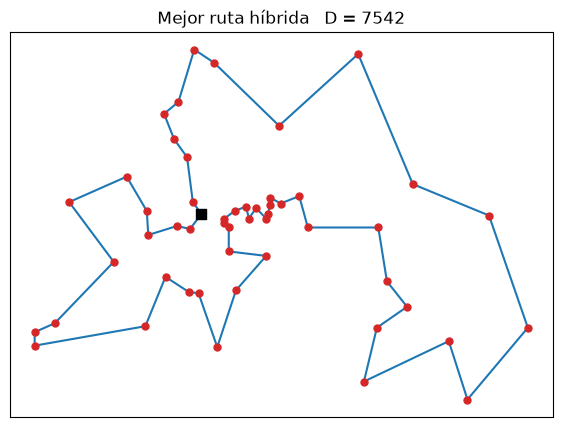

In [13]:
best_hibrido, D_hibrido, historial_hibrido = algoritmo_genetico(
    matriz_berlin, **parametros, mejora_local=True
)

mostrar_resultado(best_hibrido, D_hibrido)
print(f"Error respecto al óptimo: {100 * (D_hibrido - OPTIMO_BERLIN) / OPTIMO_BERLIN:.2f}%")

graficar_ruta(coordenadas_berlin, best_hibrido, f"Mejor ruta híbrida   D = {D_hibrido:.0f}")
plt.show()

In [14]:
lado, separacion = 6, 10
x, y = np.meshgrid(np.arange(lado) * separacion, np.arange(lado) * separacion)
coordenadas_reticula = np.column_stack([x.ravel(), y.ravel()]).astype(float)
coordenadas_reticula, matriz_reticula = preparar_problema(coordenadas_reticula)

# Optimo de reticula par
OPTIMO_RETICULA = lado * lado * separacion

parametros_reticula = {
    "N": 500,
    "maxIter": 1000,
    "seleccion": "torneo",
    "k": 3,
    "s": 0.1,
    "c": 0.5,
    "m": 0.4,
    "semilla": 1,
}
print("Ciudades:", len(coordenadas_reticula))
print("Distancia óptima:", OPTIMO_RETICULA)

Ciudades: 36
Distancia óptima: 360


In [15]:
inicio = time.time()
best_reticula, D_reticula, historial_reticula = algoritmo_genetico(matriz_reticula, **parametros_reticula)
duracion = time.time() - inicio

mostrar_resultado(best_reticula, D_reticula)
print(f"Error respecto al óptimo: {100 * (D_reticula - OPTIMO_RETICULA) / OPTIMO_RETICULA:.2f}%")
print(f"Tiempo: {duracion:.1f} s")

best = 1 -> 2 -> 3 -> 4 -> 5 -> 6 -> 12 -> 11 -> 17 -> 18 -> 24 -> 23 -> 22 -> 28 -> 29 -> 30 -> 36 -> 35 -> 34 -> 33 -> 27 -> 26 -> 32 -> 31 -> 25 -> 19 -> 20 -> 21 -> 15 -> 16 -> 10 -> 9 -> 8 -> 14 -> 13 -> 7 -> 1
D = 360.00
Error respecto al óptimo: 0.00%
Tiempo: 10.0 s


In [16]:
animar_evolucion(coordenadas_reticula, historial_reticula)

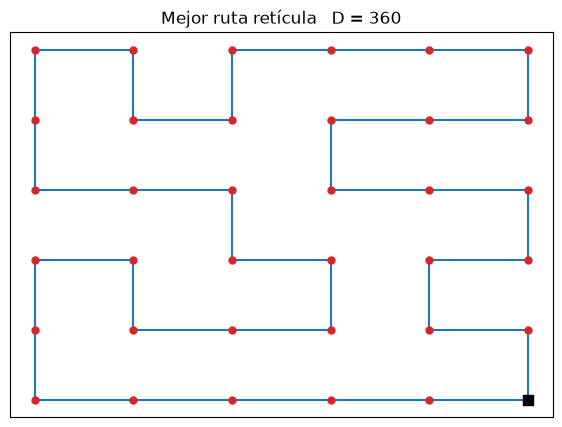

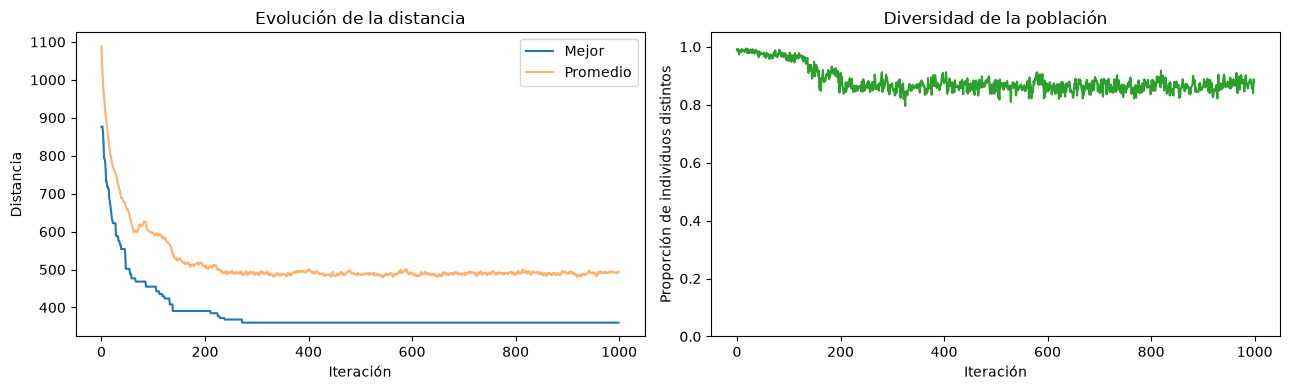

In [17]:
graficar_ruta(coordenadas_reticula, best_reticula, f"Mejor ruta retícula   D = {D_reticula:.0f}")
plt.show()
graficar_convergencia(historial_reticula)

In [18]:
# Varias semillas
for semilla in [1, 2, 3]:
    ajustes = {**parametros_reticula, "semilla": semilla}
    _, d_puro, _ = algoritmo_genetico(matriz_reticula, **ajustes)
    _, d_hibrido, _ = algoritmo_genetico(matriz_reticula, **ajustes, mejora_local=True)
    print(f"Semilla {semilla}   genético D = {d_puro:.2f}   híbrido D = {d_hibrido:.2f}")

Semilla 1   genético D = 360.00   híbrido D = 360.00


Semilla 2   genético D = 368.28   híbrido D = 360.00


Semilla 3   genético D = 368.28   híbrido D = 360.00
